In [2]:
import pandas as pd

# Pegar dados do Enade de Ciência da Computação na UNIFOR

In [3]:
course_codes = pd.read_csv('../data/MICRODADOS_CADASTRO_CURSOS_2021.CSV', encoding='ISO-8859-1', sep=';')
universities = pd.read_csv('../data/MICRODADOS_CADASTRO_IES_2021.CSV', encoding='ISO-8859-1', sep=';')
courses = pd.merge(course_codes, universities, on='CO_IES')
courses[['CO_IES', 'SG_IES', 'NO_IES', 'NO_CURSO', 'CO_CURSO']]

/tmp/ipykernel_10352/4145937453.py:1: DtypeWarning: Columns (1: NO_REGIAO, 3: NO_UF, 4: SG_UF, 6: NO_MUNICIPIO) have mixed types. Specify dtype option on import or set low_memory=False.
  course_codes = pd.read_csv('../data/MICRODADOS_CADASTRO_CURSOS_2021.CSV', encoding='ISO-8859-1', sep=';')


,CO_IES,SG_IES,NO_IES,NO_CURSO,CO_CURSO
0,1,UFMT,UNIVERSIDADE FEDERAL DE MATO GROSSO,Administração Pública,1113617
1,1,UFMT,UNIVERSIDADE FEDERAL DE MATO GROSSO,Ciências Naturais E Matemática,114386
2,1,UFMT,UNIVERSIDADE FEDERAL DE MATO GROSSO,Matemática,1357965
3,1,UFMT,UNIVERSIDADE FEDERAL DE MATO GROSSO,Pedagogia,105652
4,1,UFMT,UNIVERSIDADE FEDERAL DE MATO GROSSO,Tecnologia Educacional,1425400
...,...,...,...,...,...
444781,953,UNIMES,UNIVERSIDADE METROPOLITANA DE SANTOS,Gestão Pública,1268553
444782,953,UNIMES,UNIVERSIDADE METROPOLITANA DE SANTOS,Letras - Língua Portuguesa,1357716
444783,953,UNIMES,UNIVERSIDADE METROPOLITANA DE SANTOS,Matemática,100724
444784,953,UNIMES,UNIVERSIDADE METROPOLITANA DE SANTOS,Música,1190335


In [4]:
UNIFOR_CO = courses[courses['SG_IES'] == 'UNIFOR']['CO_IES'].values[0]

f'Código da UNIFOR é {UNIFOR_CO}'

'Código da UNIFOR é 555'

In [5]:
courses_in_unifor = courses[courses['CO_IES'] == UNIFOR_CO]
courses_in_unifor[['NO_CURSO', 'CO_CURSO']]

,NO_CURSO,CO_CURSO
2696,Administração,1572759
2697,Análise E Desenvolvimento De Sistemas,1575331
2698,Ciências Contábeis,1572766
2699,Gestão Financeira,1568178
2700,Marketing Digital,1571354
80442,Abi - Educação Física,5001676
80443,Administração,11721
80444,Análise E Desenvolvimento De Sistemas,1172346
80445,Arquitetura E Urbanismo,18324
80446,Cinema E Audiovisual,113088


In [6]:
computer_science_like = courses_in_unifor['NO_CURSO'].str.contains('da computa', case=False, na=False)
result = courses_in_unifor[computer_science_like][['NO_CURSO', 'CO_CURSO']]

COMPUTER_SCIENCE_CODE = result['CO_CURSO'].values[0]
print(f'O código do curso de Ciência da Computação na UNIFOR é {COMPUTER_SCIENCE_CODE}')

result

O código do curso de Ciência da Computação na UNIFOR é 11730


,NO_CURSO,CO_CURSO
80447,Ciência Da Computação,11730


# Como se distribui a renda familiar dos concluintes da Ciência da Computação da UNIFOR

**Variável**: QE_I08

**Hipótese**: Mais da metade dos respondentes está nas faixas de renda de 10 a 30 salários mínimos ou acima de 30 salários mínimos.

In [7]:
qe_i08 = pd.read_csv('../data/2021/microdados2021_arq14.txt', encoding='ISO-8859-1', sep=';')
qe_i08 = qe_i08[qe_i08['CO_CURSO'] == COMPUTER_SCIENCE_CODE]
qe_i08_labels = {
    'A': 'Até 1,5 salário mínimo (até R$ 1.650,00).',
    'B': 'De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ 3.300,00).',
    'C': 'De 3 a 4,5 salários mínimos (R$ 3.300,01 a R$ 4.950,00).',
    'D': 'De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ 6.600,00).',
    'E': 'De 6 a 10 salários mínimos (R$ 6.600,01 a R$ 11.000,00).',
    'F': 'De 10 a 30 salários mínimos (R$ 11.000,01 a R$ 33.000,00).',
    'G': 'Acima de 30 salários mínimos (mais de R$ 33.000,00).',
}
qe_i08['QE_I08_LABEL'] = qe_i08['QE_I08'].map(qe_i08_labels)
qe_i08

,NU_ANO,CO_CURSO,QE_I08,QE_I08_LABEL
21734,2021,11730,A,"Até 1,5 salário mínimo (até R$ 1.650,00)."
69587,2021,11730,A,"Até 1,5 salário mínimo (até R$ 1.650,00)."
135371,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
136438,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
143107,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
184504,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
204328,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
332729,2021,11730,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ ..."
340383,2021,11730,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ ..."
341193,2021,11730,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ ..."


In [8]:
qe_i08_labels = {
    'A': 'Até 1,5 salário mínimo (até R$ 1.650,00).',
    'B': 'De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ 3.300,00).',
    'C': 'De 3 a 4,5 salários mínimos (R$ 3.300,01 a R$ 4.950,00).',
    'D': 'De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ 6.600,00).',
    'E': 'De 6 a 10 salários mínimos (R$ 6.600,01 a R$ 11.000,00).',
    'F': 'De 10 a 30 salários mínimos (R$ 11.000,01 a R$ 33.000,00).',
    'G': 'Acima de 30 salários mínimos (mais de R$ 33.000,00).',
}
qe_i08['QE_I08_LABEL'] = qe_i08['QE_I08'].map(qe_i08_labels)
qe_i08

,NU_ANO,CO_CURSO,QE_I08,QE_I08_LABEL
21734,2021,11730,A,"Até 1,5 salário mínimo (até R$ 1.650,00)."
69587,2021,11730,A,"Até 1,5 salário mínimo (até R$ 1.650,00)."
135371,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
136438,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
143107,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
184504,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
204328,2021,11730,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ ..."
332729,2021,11730,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ ..."
340383,2021,11730,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ ..."
341193,2021,11730,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ ..."


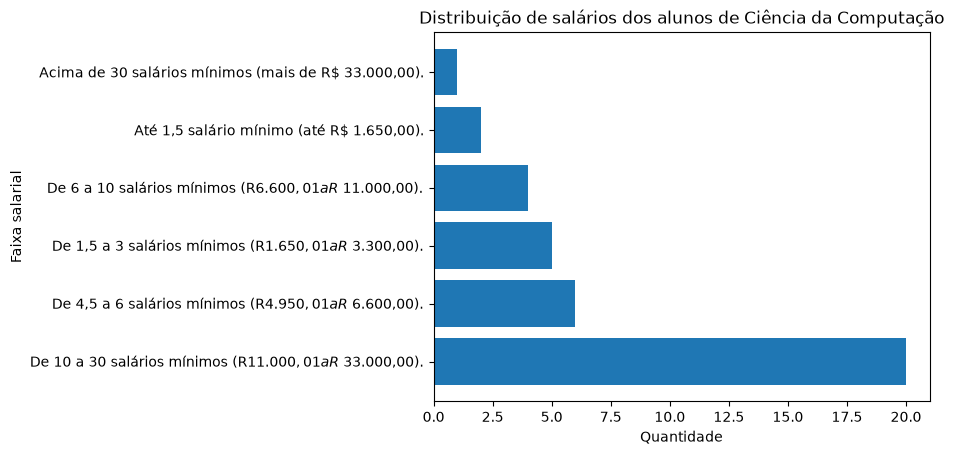

In [9]:
from matplotlib import pyplot as plt

plt.barh(qe_i08['QE_I08_LABEL'].value_counts().index, qe_i08['QE_I08_LABEL'].value_counts().values)
plt.ylabel('Faixa salarial')
plt.xlabel('Quantidade')
plt.title('Distribuição de salários dos alunos de Ciência da Computação')
plt.show()

## Percentuais sobre as respostas válidas de Ciência da Computação da UNIFOR.

In [10]:
respostas_qe_i08 = qe_i08['QE_I08']
contagens_qe_i08 = respostas_qe_i08.value_counts().reindex(qe_i08_labels, fill_value=0)
total_validas_qe_i08 = contagens_qe_i08.sum()

tabela_qe_i08 = pd.DataFrame({
    'QE_I08': list(qe_i08_labels),
    'Label': list(qe_i08_labels.values()),
    'Quantidade': contagens_qe_i08.to_numpy(),
})
tabela_qe_i08['Porcentagem (%)'] = (
    tabela_qe_i08['Quantidade'] / total_validas_qe_i08 * 100
    if total_validas_qe_i08 else float('nan')
)
print(f'Base: {total_validas_qe_i08} respostas válidas; '
      f'{(~respostas_qe_i08.isin(qe_i08_labels)).sum()} respostas ausentes ou inválidas excluídas.')
tabela_qe_i08.style.format({'Porcentagem (%)': '{:.2f}%'})

Base: 38 respostas válidas; 20 respostas ausentes ou inválidas excluídas.


,QE_I08,Label,Quantidade,Porcentagem (%)
0,A,"Até 1,5 salário mínimo (até R$ 1.650,00).",2,5.26%
1,B,"De 1,5 a 3 salários mínimos (R$ 1.650,01 a R$ 3.300,00).",5,13.16%
2,C,"De 3 a 4,5 salários mínimos (R$ 3.300,01 a R$ 4.950,00).",0,0.00%
3,D,"De 4,5 a 6 salários mínimos (R$ 4.950,01 a R$ 6.600,00).",6,15.79%
4,E,"De 6 a 10 salários mínimos (R$ 6.600,01 a R$ 11.000,00).",4,10.53%
5,F,"De 10 a 30 salários mínimos (R$ 11.000,01 a R$ 33.000,00).",20,52.63%
6,G,"Acima de 30 salários mínimos (mais de R$ 33.000,00).",1,2.63%
